# Image Classification using Vision Transformers (ViT) on CIFAR-10

**Configuration:** ViT-Small, 8×8 patches, all 12 transformer blocks unfrozen.

This notebook fine-tunes a pretrained `timm` ViT-Small model on a balanced subset of CIFAR-10, evaluates it, and visualizes final-block patch attention.

**Recommended runtime:** Google Colab with GPU enabled. Training on CPU can be slow.

In [ ]:
%pip install -q timm

Note: you may need to restart the kernel to use updated packages.


## 1. Install and import required libraries

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import timm
import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, Subset
from collections import defaultdict

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

Device: cuda
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128


## 2. Define class labels and preprocessing

In [ ]:
classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

IMG_SIZE = 224
BATCH_SIZE = 8

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

## 3. Load CIFAR-10 dataset

In [ ]:
train_f = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_f = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_f))
print("Testing images:", len(test_f))
print("Classes:", train_f.classes)

100%|██████████| 170M/170M [19:26<00:00, 146kB/s] 


Training images: 50000
Testing images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 4. Create a balanced subset
Select 500 training images and 100 test images per class.

In [ ]:
def balanced_indices(dataset, n):
    idx = defaultdict(list)
    for i, y in enumerate(dataset.targets):
        if len(idx[y]) < n:
            idx[y].append(i)
    return [i for c in range(10) for i in idx[c]]

train_data = Subset(train_f, balanced_indices(train_f, 500))
test_data = Subset(test_f, balanced_indices(test_f, 100))

print("Subset training size:", len(train_data))
print("Subset testing size:", len(test_data))

Subset training size: 5000
Subset testing size: 1000


## 5. Create DataLoaders

In [ ]:
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 625
Testing batches: 125


## 6. Visualize sample images

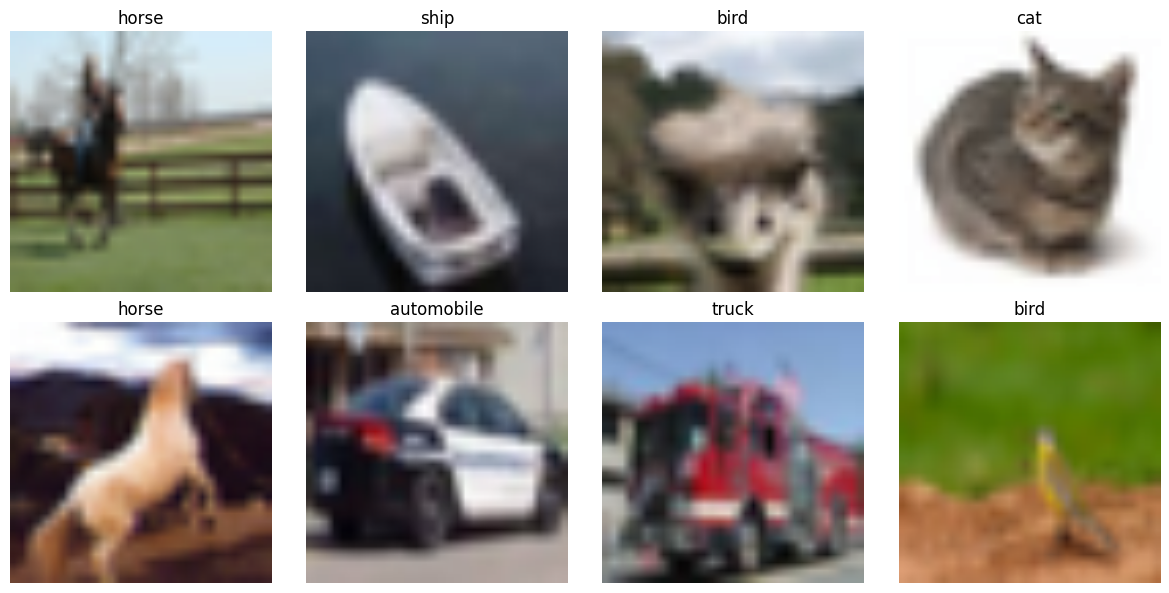

In [ ]:
mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])

def denorm(t):
    return np.clip(t.permute(1, 2, 0).cpu().numpy() * std + mean, 0, 1)

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(denorm(images[i]))
    ax.set_title(classes[labels[i]])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Load pretrained ViT-Small
The selected checkpoint uses 8×8 patches and 12 transformer blocks. The pretrained checkpoint may differ from the exact one used in the Virtual Labs simulation.

In [ ]:
model = timm.create_model("vit_small_patch8_224.dino", pretrained=True, num_classes=10).to(device)

print("Transformer blocks:", len(model.blocks))
print("Patch size:", model.patch_embed.patch_size)

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Transformer blocks: 12
Patch size: (8, 8)


## 8. Freeze and unfreeze layers
All 12 transformer blocks and the final normalization and classification head are trainable. The patch embedding remains frozen.

In [ ]:
for p in model.parameters():
    p.requires_grad = False
for m in (model.blocks, model.norm, model.head):
    for p in m.parameters():
        p.requires_grad = True

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())

print(f"Trainable parameters: {trainable:,}")
print(f"Total parameters: {total:,}")
print("Unfrozen transformer blocks:", len(model.blocks))

Trainable parameters: 21,298,186
Total parameters: 21,674,122
Unfrozen transformer blocks: 12


## 9. Define loss function and optimizer

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-5, weight_decay=0.05
)
EPOCHS = 3

## 10. Train the model

In [ ]:
train_losses, train_accuracies = [], []

for epoch in range(EPOCHS):
    model.train()
    running_loss = correct = total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_losses.append(running_loss / total)
    train_accuracies.append(100 * correct / total)
    print(f"Epoch [{epoch+1}/{EPOCHS}] Loss: {train_losses[-1]:.4f} Accuracy: {train_accuracies[-1]:.2f}%")

Epoch [1/3] Loss: 0.5150 Accuracy: 84.04%
Epoch [2/3] Loss: 0.0439 Accuracy: 98.96%
Epoch [3/3] Loss: 0.0074 Accuracy: 99.94%


## 11. Plot training performance

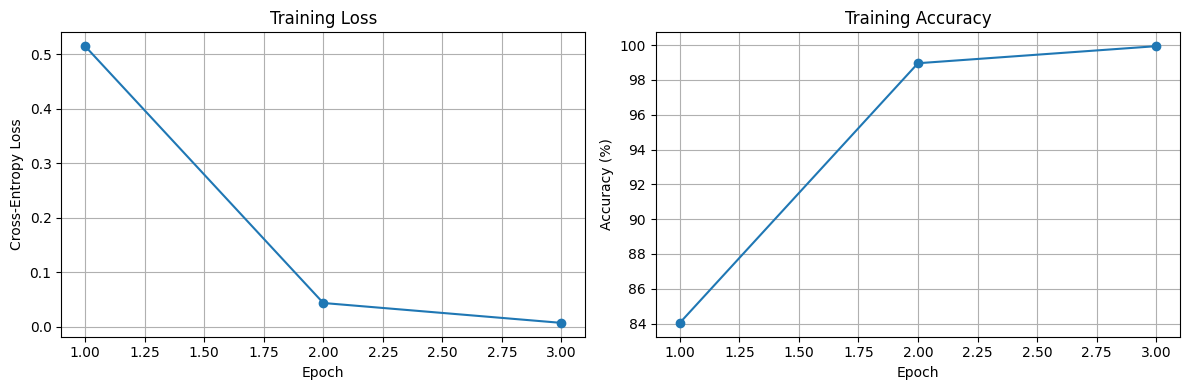

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, data, title, ylabel in zip(
    axes, (train_losses, train_accuracies),
    ("Training Loss", "Training Accuracy"),
    ("Cross-Entropy Loss", "Accuracy (%)")
):
    ax.plot(range(1, len(data) + 1), data, marker="o")
    ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
    ax.grid(True)

plt.tight_layout()
plt.show()

## 12. Evaluate on the test subset

In [ ]:
model.eval()
test_loss = correct = total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)

        test_loss += criterion(outputs, labels).item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

print(f"Test Loss: {test_loss / total:.4f}")
print(f"Test Accuracy: {100 * correct / total:.2f}%")

Test Loss: 0.1164
Test Accuracy: 96.30%


## 13. Calculate class-wise accuracy

In [ ]:
class_correct, class_total = [0] * 10, [0] * 10

with torch.no_grad():
    for images, labels in test_loader:
        preds = model(images.to(device)).argmax(1).cpu()
        for y, p in zip(labels, preds):
            class_total[y] += 1
            class_correct[y] += int(y == p)

for i, name in enumerate(classes):
    print(f"{name:12s}: {100 * class_correct[i] / class_total[i]:.2f}%")

airplane    : 98.00%
automobile  : 98.00%
bird        : 93.00%
cat         : 94.00%
deer        : 95.00%
dog         : 94.00%
frog        : 97.00%
horse       : 97.00%
ship        : 99.00%
truck       : 98.00%


## 14. Extract final-block self-attention weights

In [ ]:
store = {}
handle = model.blocks[-1].register_forward_pre_hook(lambda m, inp: store.update(x=inp[0].detach()))

images, labels = next(iter(test_loader))
image = images[:1].to(device)
with torch.no_grad():
    model(image)
handle.remove()

x, attn = store["x"], model.blocks[-1].attn
B, N, C = x.shape
h = attn.num_heads

q, k, v = attn.qkv(x).reshape(B, N, 3, h, C // h).permute(2, 0, 3, 1, 4).unbind(0)
weights = ((q * attn.scale) @ k.transpose(-2, -1)).softmax(dim=-1)

print("Token input shape:", x.shape)
print("Attention shape:", weights.shape)

Token input shape: torch.Size([1, 785, 384])
Attention shape: torch.Size([1, 6, 785, 785])


## 15. Visualize patch-level attention maps

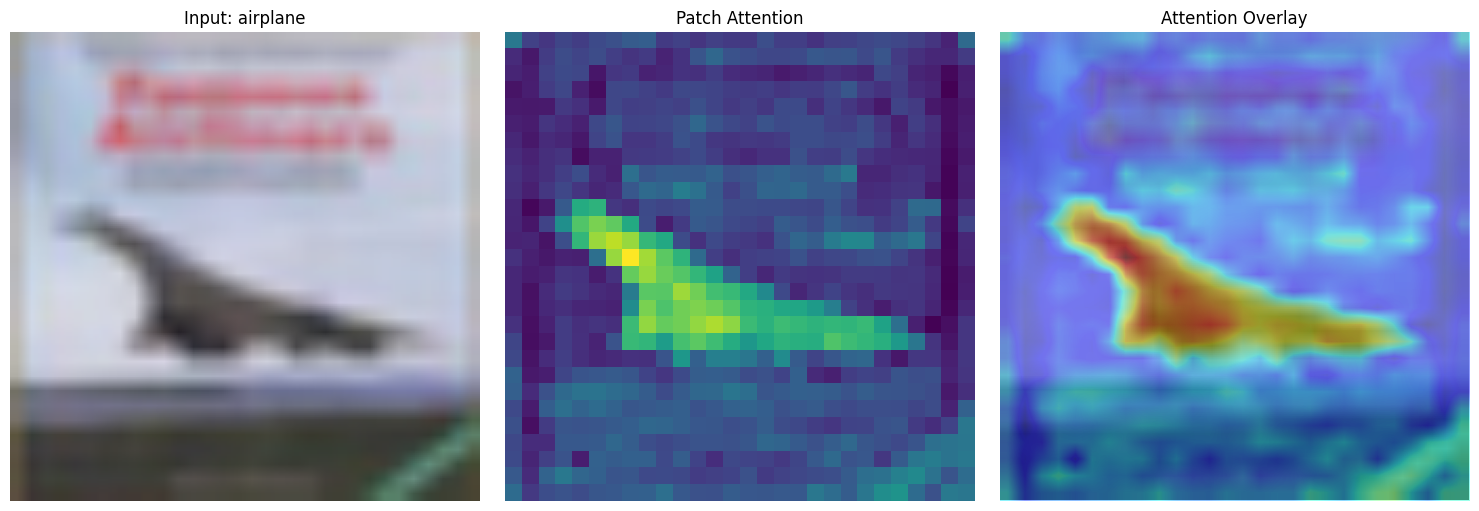

In [ ]:
# 15
g = IMG_SIZE // 8
amap = weights[0, :, 0, 1:].mean(0).detach().reshape(g, g).cpu().numpy()
amap = (amap - amap.min()) / (amap.max() - amap.min() + 1e-8)
img = denorm(image[0])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img);  axes[0].set_title(f"Input: {classes[labels[0]]}")
axes[1].imshow(amap, cmap="viridis");  axes[1].set_title("Patch Attention")
axes[2].imshow(img)
axes[2].imshow(amap, cmap="jet", alpha=0.45, extent=(0, IMG_SIZE, IMG_SIZE, 0), interpolation="bilinear")
axes[2].set_title("Attention Overlay")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

## 16. Display the original 8×8 patch grid

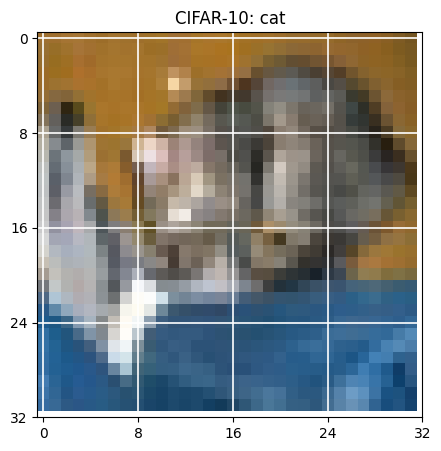

In [ ]:
# 16
img0, y0 = torchvision.datasets.CIFAR10("./data", train=False)[0]

plt.figure(figsize=(5, 5))
plt.imshow(img0)
plt.xticks(np.arange(0, 33, 8))
plt.yticks(np.arange(0, 33, 8))
plt.grid(color="white", linewidth=1.2)
plt.title(f"CIFAR-10: {classes[y0]}")
plt.show()